# Bike Sharing Demand: Descriptive, Visual and Predictive Analysis

**Dataset:** UCI Bike Sharing Dataset — Capital Bikeshare, Washington D.C.
(Fanaee-T & Gama, 2013). 17,379 hourly records spanning 1 Jan 2011 – 31 Dec 2012.

**Question this project answers:** what drives demand for shared bikes, and can
the next hour's demand be predicted from the calendar and the weather forecast?

**What is covered**

| Part | Content |
|---|---|
| 1 | Data loading and quality assessment |
| 2 | Descriptive analysis — central tendency, spread, shape, segment comparisons |
| 3 | Data visualization — 8 figures on a single validated design system |
| 4 | Predictive analysis — 4 regression models, chronological vs random evaluation |
| 5 | Findings, recommendations and limitations |

All analysis code lives in `../src/` and is imported here, so the notebook,
the PDF report and the slide deck are generated from one single source of truth.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import inspect
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

import viz_style as vs
import data_prep, descriptive, modeling

vs.apply_style()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

FIG = Path.cwd().parent / "figures"
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.1


---
## 1. Loading the data

The raw files ship with min–max normalised weather columns. `data_prep` restores
them to physical units (°C, %, km/h) and attaches readable labels, so every
table and chart downstream is directly interpretable.

In [2]:
hourly = data_prep.load_hourly()
daily = data_prep.load_daily()

print(f"Hourly records : {hourly.shape[0]:,} rows x {hourly.shape[1]} columns")
print(f"Daily records  : {daily.shape[0]:,} rows x {daily.shape[1]} columns")
print(f"Period covered : {hourly['dteday'].min().date()} to {hourly['dteday'].max().date()}")

hourly[["timestamp", "season_name", "weather_name", "temp_c", "humidity",
        "wind_kmh", "casual", "registered", "cnt"]].head()

Hourly records : 17,379 rows x 29 columns
Daily records  : 731 rows x 27 columns
Period covered : 2011-01-01 to 2012-12-31


,timestamp,season_name,weather_name,temp_c,humidity,wind_kmh,casual,registered,cnt
0,2011-01-01 00:00:00,Spring,Clear / Few clouds,9.84,81.0,0.0,3,13,16
1,2011-01-01 01:00:00,Spring,Clear / Few clouds,9.02,80.0,0.0,8,32,40
2,2011-01-01 02:00:00,Spring,Clear / Few clouds,9.02,80.0,0.0,5,27,32
3,2011-01-01 03:00:00,Spring,Clear / Few clouds,9.84,75.0,0.0,3,10,13
4,2011-01-01 04:00:00,Spring,Clear / Few clouds,9.84,75.0,0.0,0,1,1


In [3]:
hourly[["cnt", "casual", "registered", "temp_c", "atemp_c",
        "humidity", "wind_kmh"]].dtypes.to_frame("dtype")

,dtype
cnt,int64
casual,int64
registered,int64
temp_c,float64
atemp_c,float64
humidity,float64
wind_kmh,float64


### 1.1 Data quality assessment

Four things are checked before any analysis: missing values, duplicate records,
calendar completeness, and whether the target is internally consistent.

In [4]:
quality = data_prep.quality_report(hourly, daily)
for k, v in quality.items():
    print(f"{k:38s} {v}")

hourly_rows                            17379
daily_rows                             731
columns                                29
date_start                             2011-01-01
date_end                               2012-12-31
missing_values                         0
duplicate_rows                         0
duplicate_timestamps                   0
expected_hours                         17544
missing_hours                          165
coverage_pct                           99.06
cnt_equals_casual_plus_registered      True
zero_demand_hours                      0


**Read-out.** The dataset is unusually clean: no missing values and no
duplicate rows. Two points still matter:

* **165 hours are absent** from the series (99.06% calendar coverage). These are
  hours with no recorded activity rather than corrupted rows, so they are left
  out rather than imputed — inventing zero-demand hours would bias every mean
  downward.
* **`cnt` is exactly `casual + registered`.** That makes both columns perfect
  predictors of the target, so both must be dropped before modelling. Leaving
  them in is the single most common mistake made with this dataset.

---
## 2. Descriptive analysis

### 2.1 Central tendency, spread and shape

In [5]:
summary = hourly[["cnt", "casual", "registered", "temp_c",
                  "humidity", "wind_kmh"]].describe().round(2)
summary

,cnt,casual,registered,temp_c,humidity,wind_kmh
count,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00
mean,189.46,35.68,153.79,20.38,62.72,12.74
std,181.39,49.31,151.36,7.89,19.29,8.20
min,1.00,0.00,0.00,0.82,0.00,0.00
25%,40.00,4.00,34.00,13.94,48.00,7.00
50%,142.00,17.00,115.00,20.50,63.00,13.00
75%,281.00,48.00,220.00,27.06,78.00,17.00
max,977.00,367.00,886.00,41.00,100.00,57.00


In [6]:
stats = descriptive.describe(hourly, daily)

print("DEMAND VOLUME")
print(f"  Total rentals over 2 years : {stats['total_rentals']:,}")
print(f"  2011 / 2012                : {stats['rentals_2011']:,} / {stats['rentals_2012']:,}")
print(f"  Year-on-year growth        : +{stats['yoy_growth_pct']}%")
print()
print("HOURLY DEMAND DISTRIBUTION")
print(f"  Mean / Median              : {stats['mean_hourly']} / {stats['median_hourly']}")
print(f"  Std. deviation             : {stats['std_hourly']}")
print(f"  Range                      : {stats['min_hourly']} to {stats['max_hourly']}")
print(f"  Coefficient of variation   : {stats['cv_pct']}%")
print(f"  Skewness / Kurtosis        : {stats['skewness']} / {stats['kurtosis']}")
print()
print("USER MIX")
print(f"  Registered share           : {stats['registered_share_pct']}%")
print(f"  Casual share               : {stats['casual_share_pct']}%")
print(f"  Casual share, weekends     : {stats['casual_share_weekend_pct']}%")
print(f"  Casual share, working days : {stats['casual_share_working_pct']}%")

DEMAND VOLUME
  Total rentals over 2 years : 3,292,679
  2011 / 2012                : 1,243,103 / 2,049,576
  Year-on-year growth        : +64.9%

HOURLY DEMAND DISTRIBUTION
  Mean / Median              : 189.5 / 142.0
  Std. deviation             : 181.4
  Range                      : 1 to 977
  Coefficient of variation   : 95.7%
  Skewness / Kurtosis        : 1.28 / 1.42

USER MIX
  Registered share           : 81.2%
  Casual share               : 18.8%
  Casual share, weekends     : 31.7%
  Casual share, working days : 13.2%


The mean (189.5) sits well above the median (142.0) and skewness is **+1.28**:
the distribution of hourly demand has a long right tail. A handful of peak
commuter hours account for a disproportionate share of all trips, which is why
the mean alone is a poor summary of a typical hour.

The coefficient of variation is **95.7%** — the standard deviation is almost as
large as the mean. Demand is not noisy-but-stable; it is genuinely structured,
and that structure is what the predictive model in Part 4 exploits.

### 2.2 Segment comparisons

In [7]:
by_season = hourly.groupby("season_name")["cnt"].agg(
    ["count", "mean", "median", "std", "max"]).round(1)
by_season = by_season.reindex(["Spring", "Summer", "Fall", "Winter"])
by_season

,count,mean,median,std,max
season_name,,,,,
Spring,4242,111.1,76.0,119.2,801
Summer,4409,208.3,165.0,188.4,957
Fall,4496,236.0,199.0,197.7,977
Winter,4232,198.9,155.5,183.0,967


In [8]:
by_weather = hourly.groupby("weather_name")["cnt"].agg(
    ["count", "mean", "median", "std", "max"]).round(1)
by_weather.reindex(["Clear / Few clouds", "Mist / Cloudy",
                    "Light snow or rain", "Heavy rain / snow"])

,count,mean,median,std,max
weather_name,,,,,
Clear / Few clouds,11413,204.9,159.0,189.5,977
Mist / Cloudy,4544,175.2,133.0,165.4,957
Light snow or rain,1419,111.6,63.0,133.8,891
Heavy rain / snow,3,74.3,36.0,77.9,164


In [9]:
print(f"Peak hour         : {stats['peak_hour']:02d}:00  "
      f"({stats['peak_hour_mean']:,.0f} rentals/hour on average)")
print(f"Quietest hour     : {stats['trough_hour']:02d}:00  "
      f"({stats['trough_hour_mean']:,.0f} rentals/hour)")
print(f"Peak-to-trough    : {stats['peak_to_trough_ratio']}x")
print()
print(f"Busiest day       : {stats['max_daily_date']}  ({stats['max_daily']:,} rentals)")
print(f"Quietest day      : {stats['min_daily_date']}  ({stats['min_daily']:,} rentals)")
print()
print(f"Clear weather     : {stats['clear_weather_mean']:,.0f} rentals/hour")
print(f"Heavy rain / snow : {stats['heavy_weather_mean']:,.0f} rentals/hour"
      f"  ({stats['weather_drop_pct']}% lower)")

Peak hour         : 17:00  (462 rentals/hour on average)
Quietest hour     : 04:00  (6 rentals/hour)
Peak-to-trough    : 72.6x

Busiest day       : 2012-09-15  (8,714 rentals)
Quietest day      : 2012-10-29  (22 rentals)

Clear weather     : 205 rentals/hour
Heavy rain / snow : 74 rentals/hour  (63.7% lower)


The quietest day in two years — **29 October 2012, 22 rentals** — is not a data
error. That is the day Hurricane Sandy made landfall and Washington D.C. shut
down. It is a useful reminder that the largest residuals a demand model produces
usually correspond to real events outside the feature set.

---
## 3. Data visualization

Every figure is drawn through `src/viz_style.py`, which encodes one design
system: a colour-vision-validated categorical palette, a single-hue sequential
ramp for magnitude, a diverging ramp with a neutral midpoint for correlation,
thin marks with rounded data-ends, hairline gridlines and selective direct
labels. Colour is assigned by the *job* it does, never cycled.

### 3.1 Demand across the day

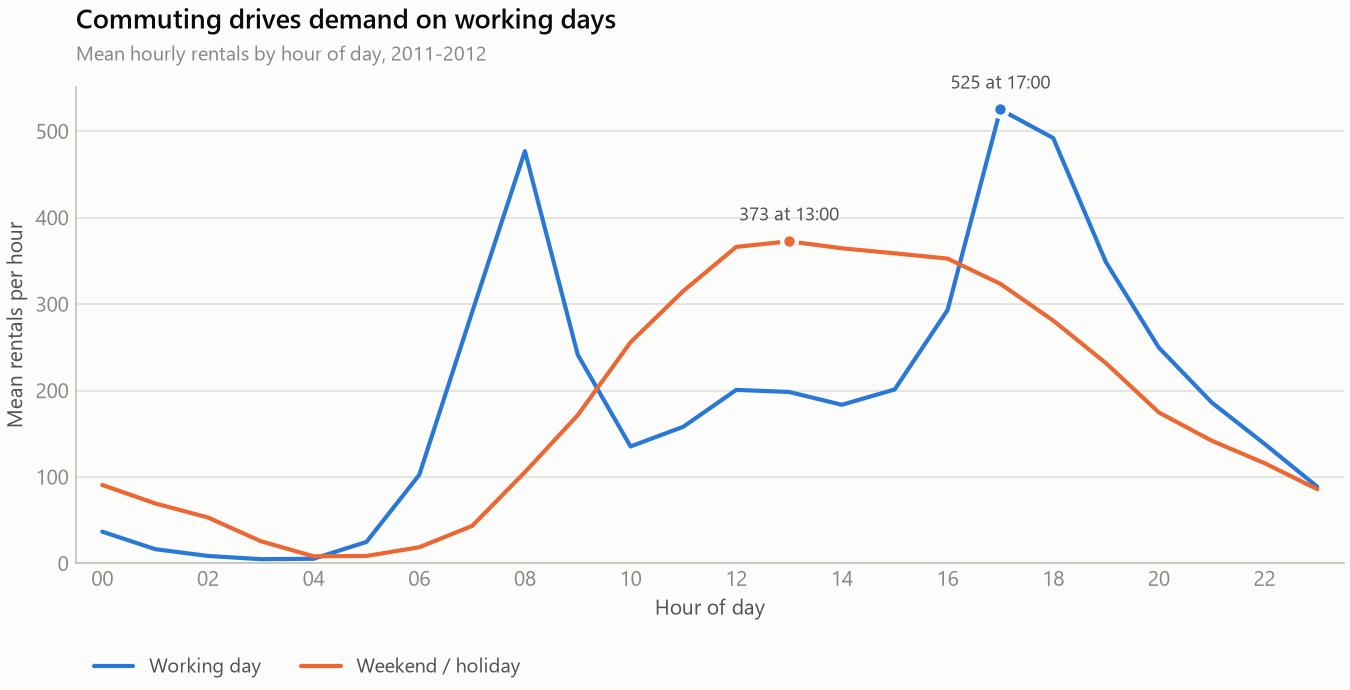

In [10]:
display(Image(str(descriptive.fig_hourly_profile(hourly))))

Two completely different demand patterns share one system. Working days produce
a sharp twin-peak commuter profile (08:00 and 17:00); weekends produce a single
broad midday hump. **Any model that ignores the working-day flag is averaging
two unrelated behaviours together.**

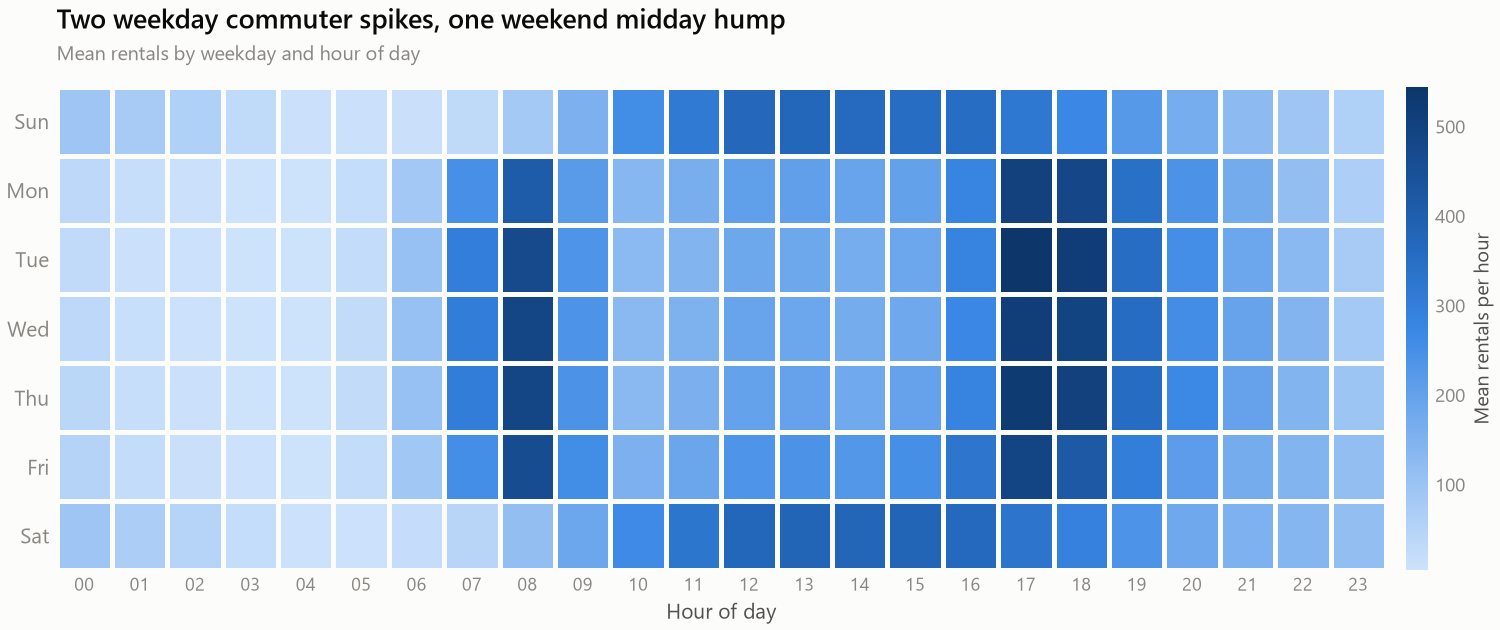

In [11]:
display(Image(str(descriptive.fig_hour_weekday_heatmap(hourly))))

### 3.2 Growth over the two-year period

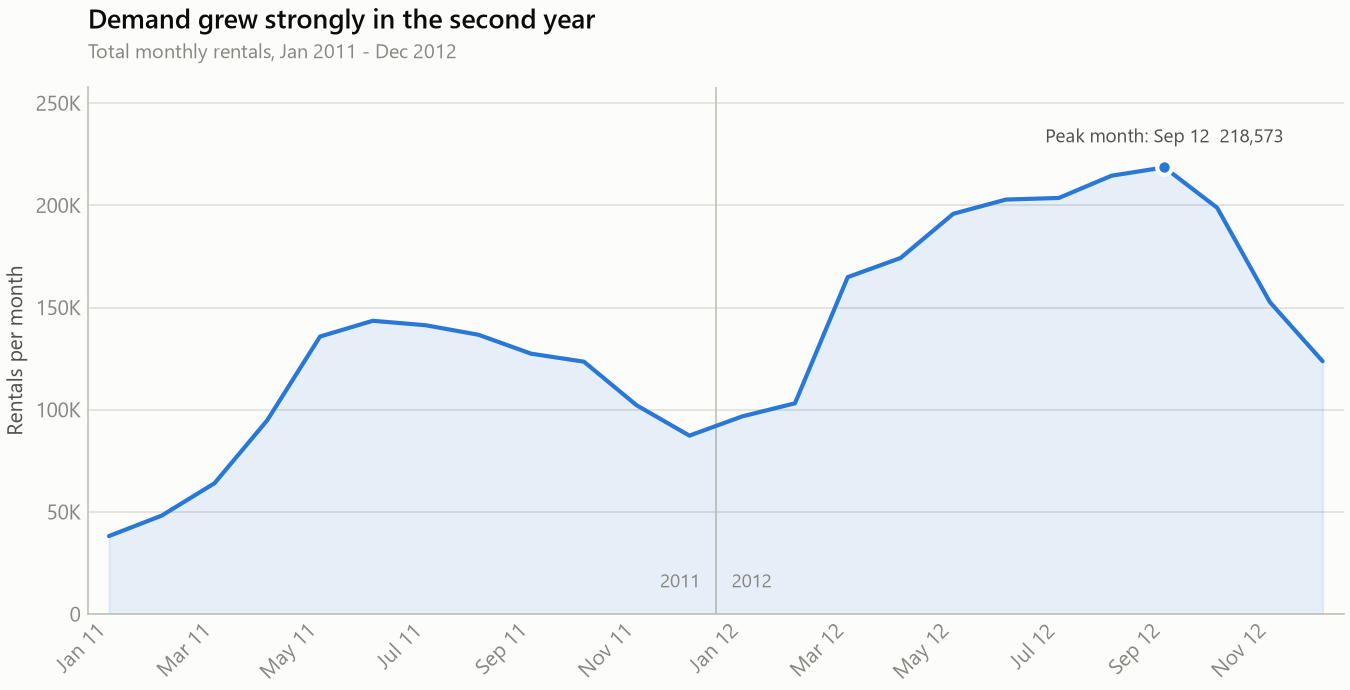

In [12]:
display(Image(str(descriptive.fig_monthly_trend(daily))))

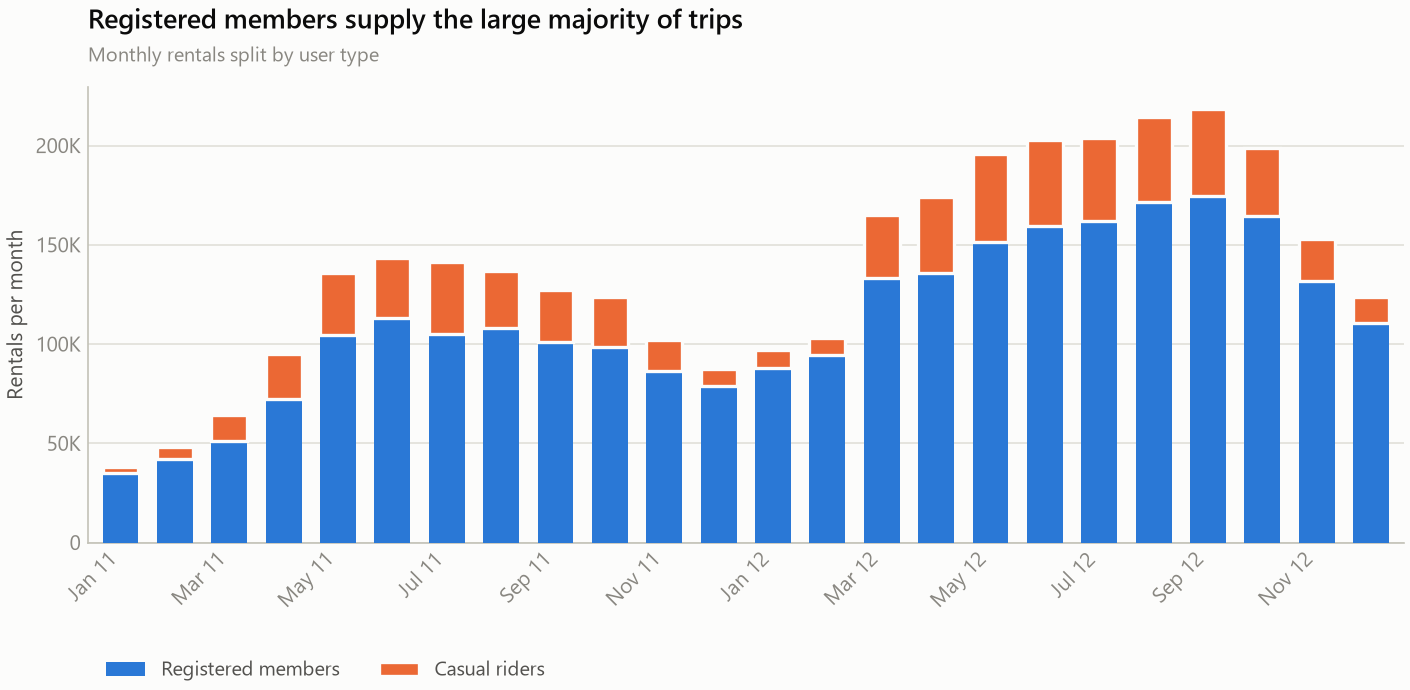

In [13]:
display(Image(str(descriptive.fig_user_mix(hourly))))

Demand grew **+64.9%** from 2011 to 2012, and the growth is overwhelmingly in
registered members — the share of trips from casual riders falls to **13.2% on
working days** against **31.7% at weekends**. The two user groups are different
businesses: commuting versus leisure.

### 3.3 Weather and seasonality

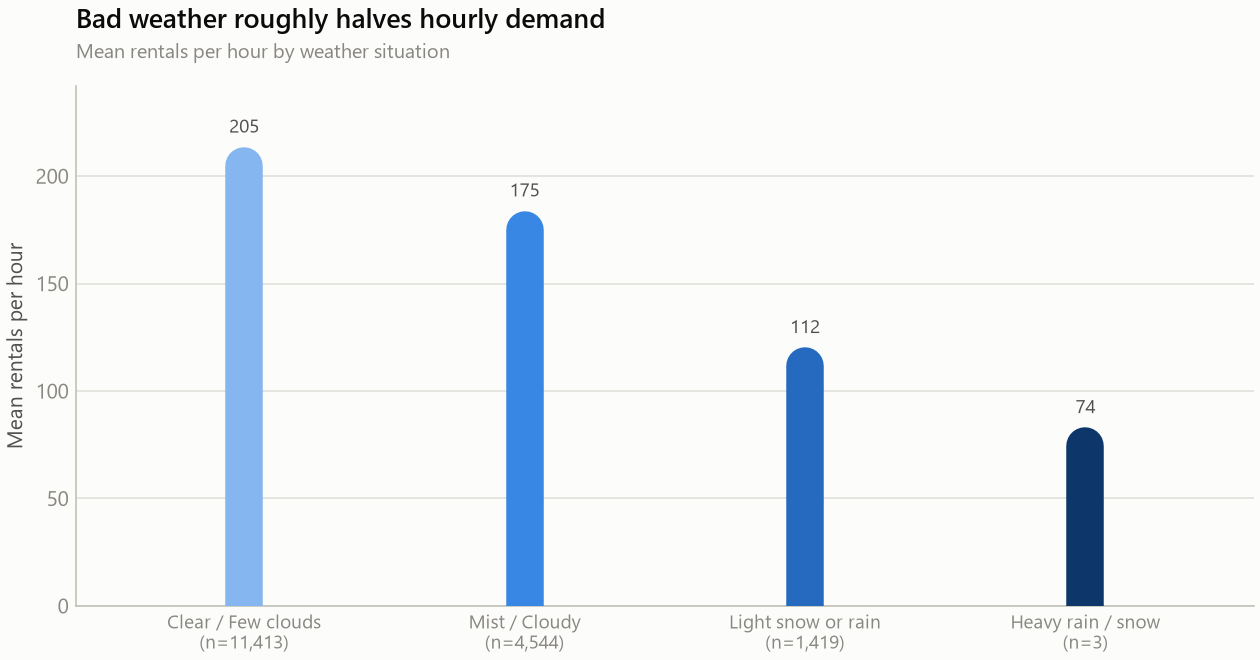

In [14]:
display(Image(str(descriptive.fig_weather_impact(hourly))))

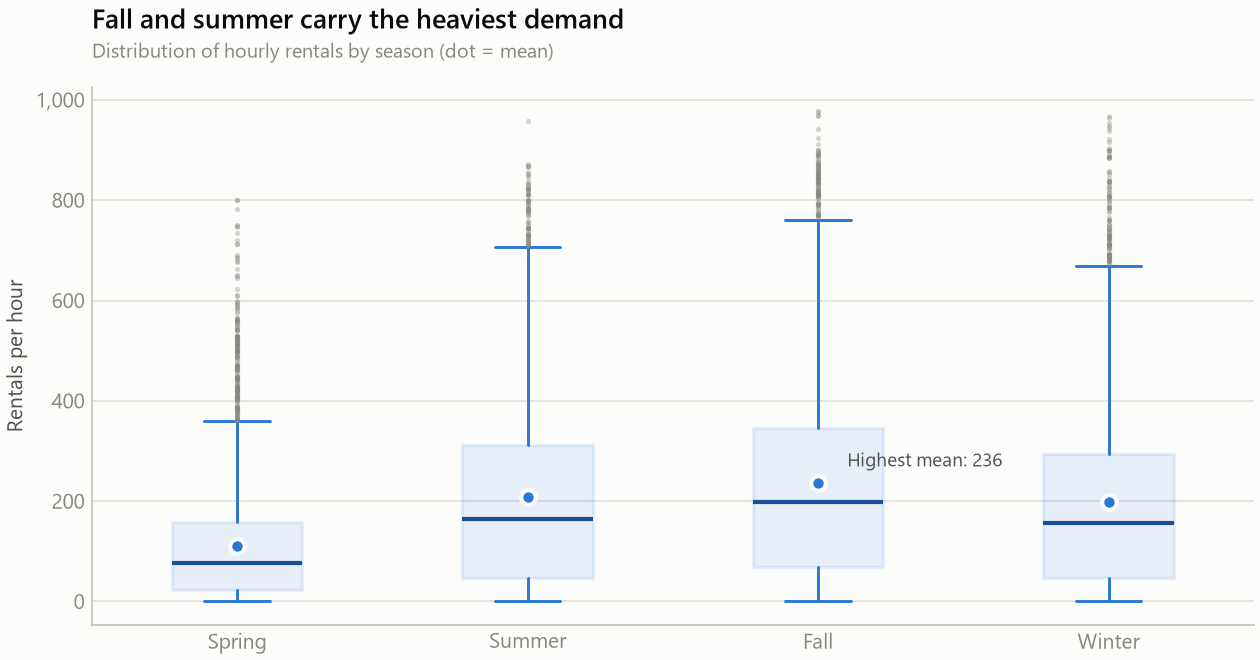

In [15]:
display(Image(str(descriptive.fig_season_distribution(hourly))))

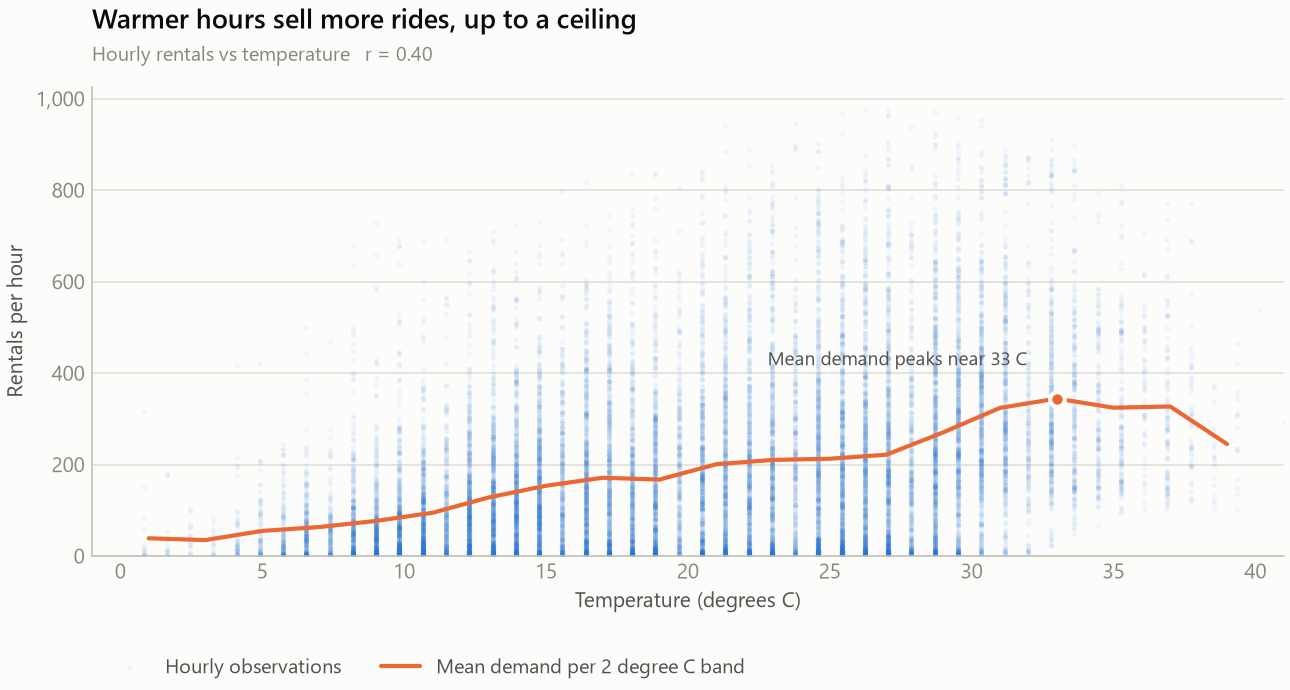

In [16]:
display(Image(str(descriptive.fig_temp_vs_demand(hourly))))

Demand rises with temperature up to roughly **33 °C** and then falls away —
the relationship is non-linear, which is the first concrete reason to expect
tree-based models to beat linear regression in Part 4.

Note the weather categories are severely unbalanced: only **3 hours** in two
years fall under "Heavy rain / snow", so that bar is a direction, not a reliable
effect size.

### 3.4 Correlation structure

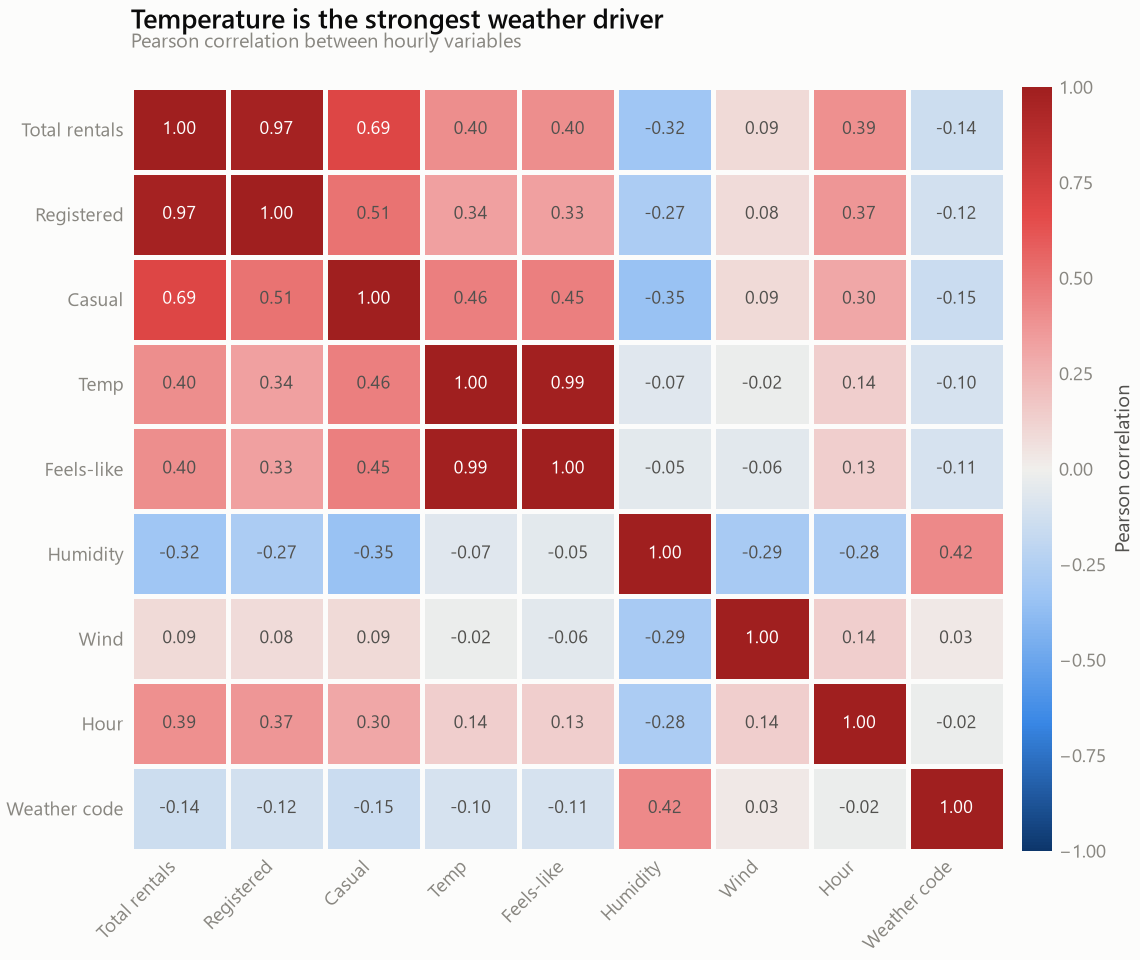

In [17]:
display(Image(str(descriptive.fig_correlation(hourly))))

Temperature is the strongest weather driver (**r = 0.40**) and humidity the
strongest negative one (**r = −0.32**). `temp` and `atemp` are correlated at
**0.99** — they carry nearly identical information, which is why their importance
scores split between them in the model below.

No single variable correlates strongly with demand on its own. That is expected:
the real signal is an *interaction* (hour × working-day × temperature), and
interactions are invisible to a correlation matrix.

---
## 4. Predictive analysis

**Task.** Regression — predict `cnt`, the number of bikes rented in a given hour,
from calendar and weather variables that would be known in advance.

### 4.1 Feature engineering

Hour 23 and hour 00 are adjacent in time but maximally distant as integers, so
cyclical variables are additionally encoded as sine/cosine pairs.

In [18]:
print(inspect.getsource(modeling.build_features))

def build_features(hourly: pd.DataFrame):
    """Return X (features), y (target) and the aligned timestamp index."""
    df = hourly.copy()
    for col, period in CYCLIC.items():
        df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / period)
        df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / period)

    cyc = [f"{c}_{fn}" for c in CYCLIC for fn in ("sin", "cos")]
    features = NUMERIC + CATEGORICAL + BINARY + cyc
    return df[features].copy(), df["cnt"].copy(), df["timestamp"].copy()



In [19]:
X, y, ts = modeling.build_features(hourly)
print(f"Feature matrix : {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"Target         : cnt  (mean {y.mean():.1f}, std {y.std():.1f})")
print()
print("Features:", ", ".join(X.columns))
print()
print("Deliberately EXCLUDED: casual, registered  "
      "(they sum exactly to the target -> leakage)")

Feature matrix : 17,379 rows x 18 features
Target         : cnt  (mean 189.5, std 181.4)

Features: temp_c, atemp_c, humidity, wind_kmh, season, weathersit, weekday, hr, mnth, holiday, workingday, yr, hr_sin, hr_cos, mnth_sin, mnth_cos, weekday_sin, weekday_cos

Deliberately EXCLUDED: casual, registered  (they sum exactly to the target -> leakage)


### 4.2 Models and validation strategy

The deployment question is *"given tomorrow's forecast, what will demand be?"* —
so the honest test is a **chronological split**: train on the earlier 80% of
hours, test on the most recent 20%, which the model has never seen. A random
split is also run, because the gap between the two is itself a finding.

In [20]:
print(inspect.getsource(modeling.make_models))

def make_models():
    """Linear baseline needs encoding; tree models take the raw columns."""
    linear_prep = ColumnTransformer(
        [("num", StandardScaler(), NUMERIC),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
          CATEGORICAL)],
        remainder="passthrough")

    return {
        "Linear Regression": Pipeline([("prep", linear_prep),
                                       ("model", LinearRegression())]),
        "Decision Tree": DecisionTreeRegressor(max_depth=12,
                                               min_samples_leaf=10,
                                               random_state=RANDOM_STATE),
        "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=None,
                                               min_samples_leaf=2, n_jobs=-1,
                                               random_state=RANDOM_STATE),
        "Gradient Boosting": HistGradientBoostingRegressor(
            max_iter=400, learning_rate=0

In [21]:
res = modeling.run(hourly)

print(f"Train : {res['train_rows']:,} hours  (up to {res['train_end']})")
print(f"Test  : {res['test_rows']:,} hours  ({res['test_start']} to {res['test_end']})")

Train : 13,903 hours  (up to 2012-08-07)
Test  : 3,476 hours  (2012-08-07 to 2012-12-31)


In [22]:
chrono = pd.DataFrame(res["results"]).T.sort_values("rmse").round(2)
chrono.columns = ["RMSE", "MAE", "R2"]
chrono

,RMSE,MAE,R2
Gradient Boosting,62.28,40.01,0.92
Random Forest,72.27,47.42,0.89
Decision Tree,86.01,56.18,0.85
Linear Regression,133.82,98.69,0.63
Baseline (train mean),232.61,174.98,-0.11


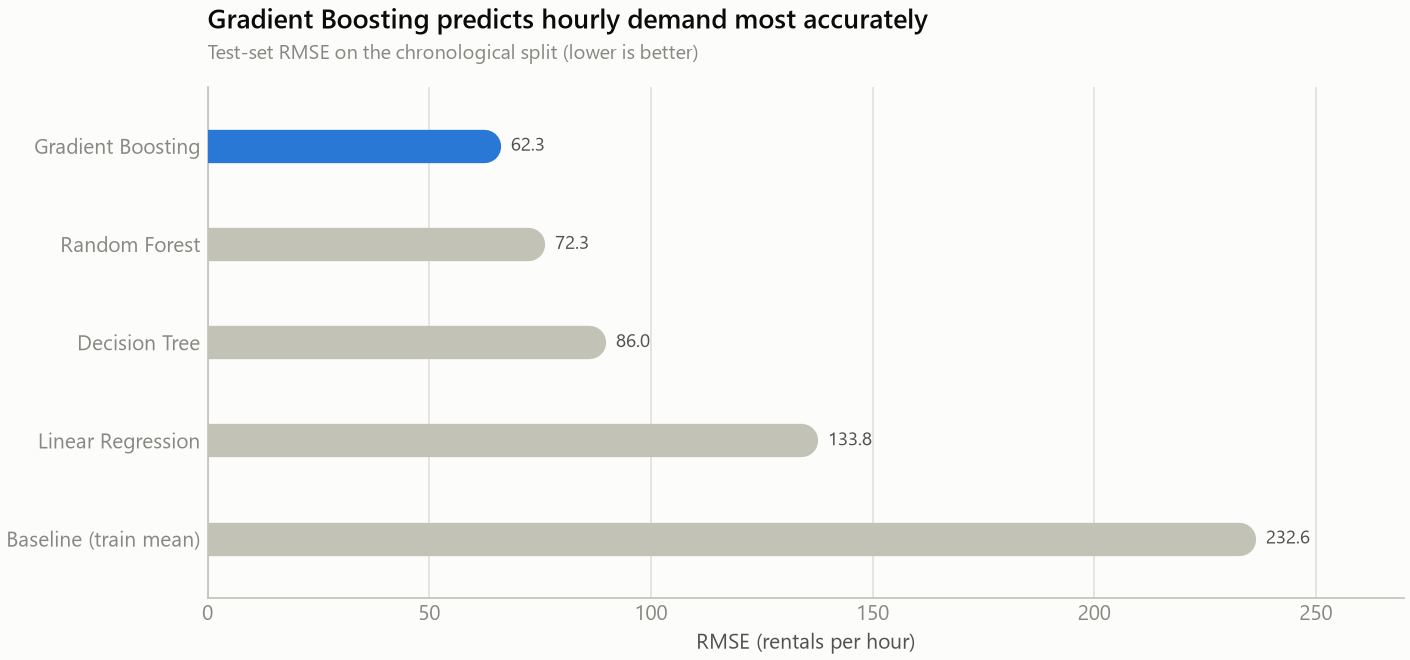

In [23]:
display(Image(str(modeling.fig_model_comparison(res))))

**Gradient Boosting wins**, with RMSE 62.3 rentals/hour and R² 0.92 on data it
has never seen — a **73% reduction in error** against the naive baseline of
always predicting the training mean.

Linear regression trails badly (RMSE 133.8). That is the expected consequence of
the non-linear temperature relationship and the hour × working-day interaction
seen in Part 3: a linear model cannot represent either.

In [24]:
rand = pd.DataFrame(res["random_results"]).T.sort_values("rmse").round(2)
rand.columns = ["RMSE", "MAE", "R2"]

comparison = pd.DataFrame({
    "Chronological split": chrono["RMSE"].drop("Baseline (train mean)"),
    "Random split": rand["RMSE"],
})
comparison["Optimism gap"] = (comparison["Chronological split"]
                              - comparison["Random split"]).round(2)
comparison

,Chronological split,Random split,Optimism gap
Gradient Boosting,62.28,38.04,24.24
Random Forest,72.27,41.32,30.95
Decision Tree,86.01,54.37,31.64
Linear Regression,133.82,97.75,36.07


**This table is the most important result in the project.** The random split
flatters every model by 15–30 RMSE, because shuffling lets the model train on
hours that sit *between* the test hours — it effectively interpolates a time
series it has already seen. Reporting the random-split number as if it were
forecasting accuracy would overstate real performance by roughly a third.

In [25]:
print("TimeSeriesSplit cross-validation (5 expanding folds), best model")
for i, v in enumerate(res["cv_rmse_folds"], 1):
    print(f"  Fold {i}: RMSE {v:7.1f}")
print(f"\n  Mean {res['cv_rmse_mean']} (+/- {res['cv_rmse_std']})")

TimeSeriesSplit cross-validation (5 expanding folds), best model
  Fold 1: RMSE    61.2
  Fold 2: RMSE    51.2
  Fold 3: RMSE   114.8
  Fold 4: RMSE    66.5
  Fold 5: RMSE    69.2

  Mean 72.6 (+/- 22.0)


Fold variance is high because early folds train on very little data *and* on a
lower-demand year. The trend upward across folds is the model learning the
2011→2012 growth, not instability.

### 4.3 What the model learned

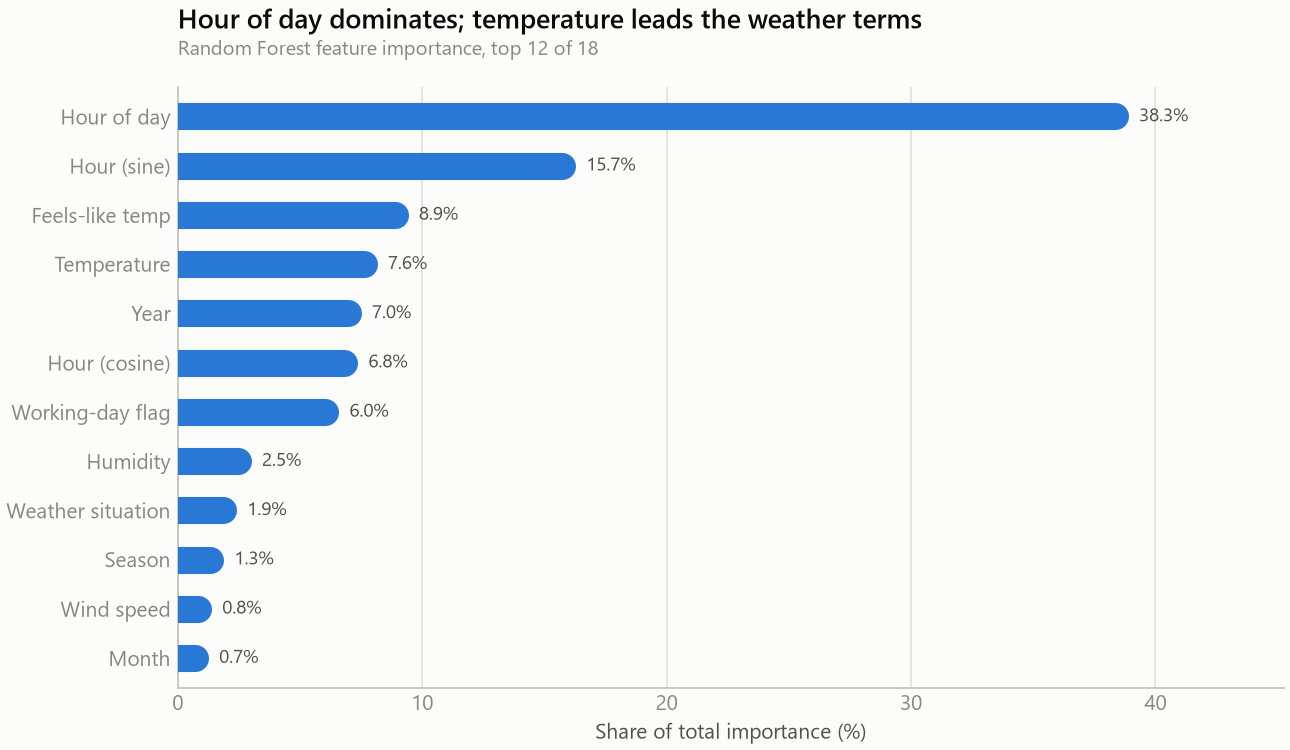

In [26]:
display(Image(str(modeling.fig_feature_importance(res))))

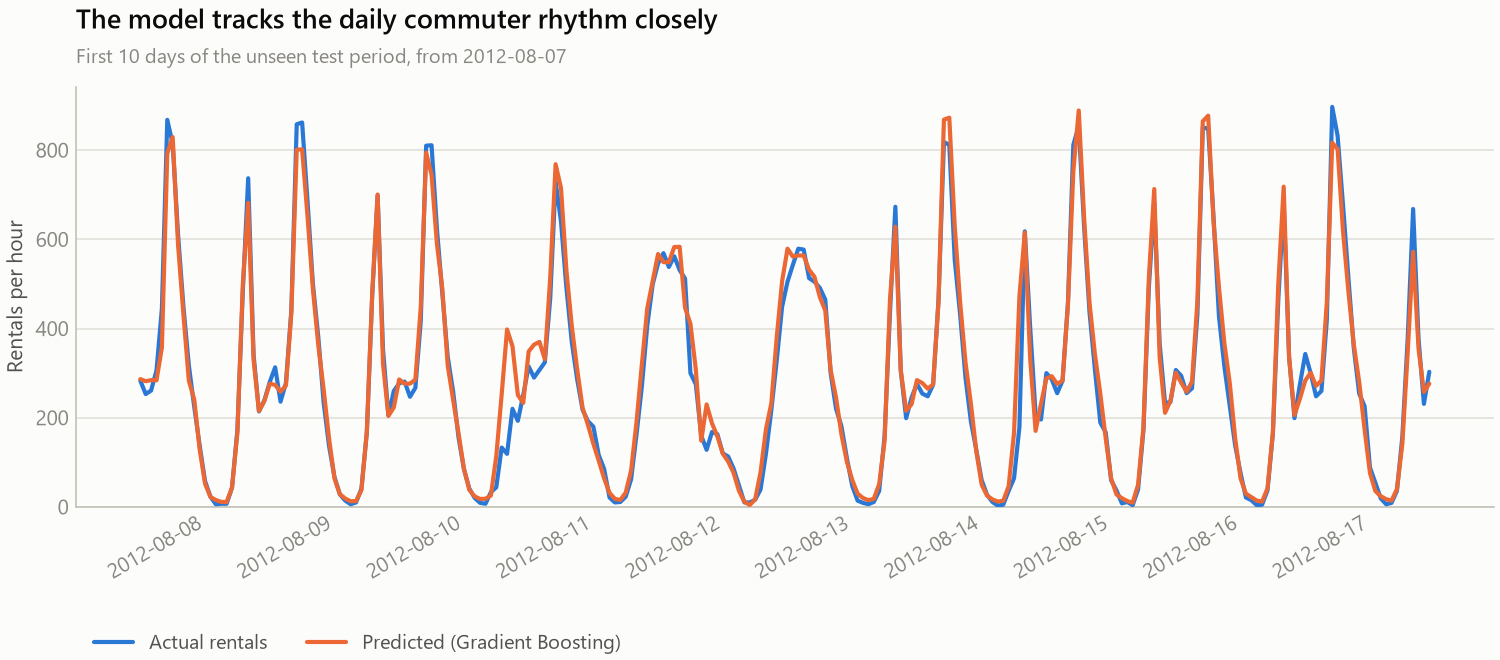

In [27]:
display(Image(str(modeling.fig_actual_vs_predicted(res))))

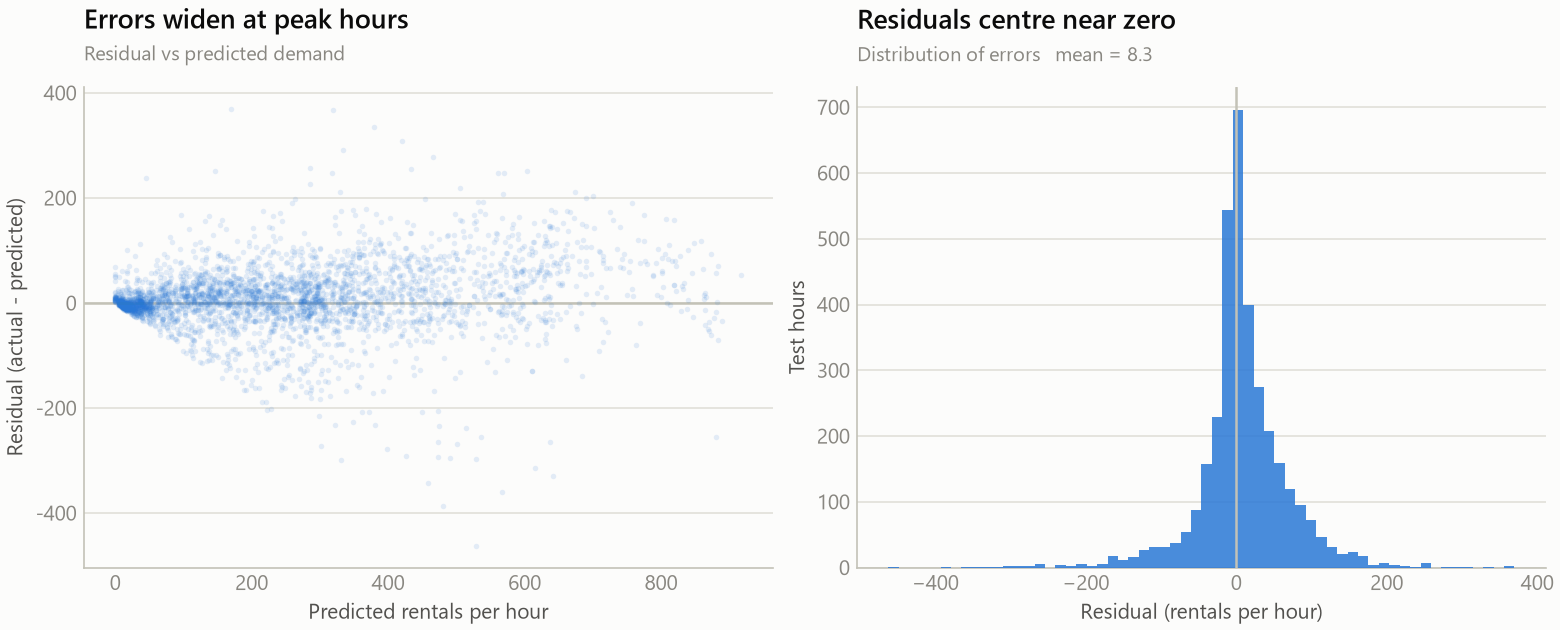

In [28]:
display(Image(str(modeling.fig_residuals(res))))

Hour of day carries **38.3%** of total importance — and together with its two
cyclical encodings, time of day accounts for roughly **61%**. Temperature terms
add about **16%**. Weather *situation* contributes only 1.9%: once temperature
and humidity are in the model, the categorical weather code adds little.

The residual plot shows clear **heteroscedasticity** — errors fan out as
predicted demand grows. The model is proportionally accurate but absolutely
less precise at peak hours, which is exactly where a bike-share operator needs
precision most.

---
## 5. Findings, recommendations and limitations

### 5.1 Key findings

1. **Demand is driven by time, not weather.** Time-of-day features carry ~61% of
   predictive importance; all weather features together carry ~20%.
2. **There are two distinct businesses.** Working days are commuter-shaped
   (twin peaks at 08:00/17:00, 13.2% casual); weekends are leisure-shaped
   (single midday hump, 31.7% casual).
3. **The service grew 64.9% year-on-year**, almost entirely through registered
   members.
4. **Weather modulates, it does not determine.** Bad weather cuts hourly demand
   by up to 63.7%, but the daily shape survives it.
5. **Hourly demand is predictable.** Gradient Boosting reaches R² 0.92 on unseen
   future hours, a 73% error reduction over the naive baseline.

### 5.2 Operational recommendations

* **Rebalance against the clock, not the forecast.** Fleet redistribution should
  finish before 07:00 and 16:00 on working days; weather is a secondary adjustment.
* **Use separate weekday and weekend plans.** One averaged schedule fits neither.
* **Target casual-to-member conversion at weekends**, where casual riders are
  31.7% of trips versus 13.2% on working days.
* **Deploy the model as an hour-ahead staffing aid**, with the caveat that its
  absolute error is largest precisely at peak hours.

### 5.3 Limitations

* **Two years, one city.** Washington D.C. 2011–2012; the growth term (`yr`) is
  fitted on two points and cannot be extrapolated beyond 2012.
* **Observed, not forecast, weather.** In production the model would receive
  *forecast* weather, which carries its own error — real accuracy would be lower
  than reported here.
* **Severe class imbalance in weather.** Only 3 hours of heavy rain/snow in the
  entire dataset.
* **Events are not modelled.** Hurricane Sandy, public holidays and city events
  drive the largest residuals and no feature captures them.
* **165 missing hours** (0.94%) were excluded rather than imputed.

### 5.4 Reproducing this analysis

```bash
pip install -r requirements.txt
python src/descriptive.py    # statistics, tables, figures 1-8
python src/modeling.py       # models, figures 9-12
```

---

**Data source:** Fanaee-T, H. & Gama, J. (2013). *Event labeling combining
ensemble detectors and background knowledge.* Progress in Artificial
Intelligence. UCI Machine Learning Repository.